In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set chart style
sns.set_theme(style="whitegrid")

# Create folders for saving results
os.makedirs("charts", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the cleaned Titanic dataset
df = pd.read_csv("data/titanic_cleaned.csv")

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (780, 14)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,s,third,man,True,southampton,no,False
1,1,1,female,38.0,1,0,71.2833,c,first,woman,False,cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,s,third,woman,False,southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,s,first,woman,False,southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,s,third,man,True,southampton,no,True


In [3]:

# Display dataset information

print("========== DATASET INFORMATION ==========")

print("\n1. Dataset Information:")
df.info()

print("\n2. Column Names:")
print(df.columns.tolist())

print("\n3. Data Types:")
print(df.dtypes)

print("\n4. Missing Values:")
print(df.isnull().sum())

print("\n5. Duplicate Rows:")
print(df.duplicated().sum())


========== DATASET INFORMATION ==========

1. Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     780 non-null    int64  
 1   pclass       780 non-null    int64  
 2   sex          780 non-null    str    
 3   age          780 non-null    float64
 4   sibsp        780 non-null    int64  
 5   parch        780 non-null    int64  
 6   fare         780 non-null    float64
 7   embarked     780 non-null    str    
 8   class        780 non-null    str    
 9   who          780 non-null    str    
 10  adult_male   780 non-null    bool   
 11  embark_town  780 non-null    str    
 12  alive        780 non-null    str    
 13  alone        780 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(6)
memory usage: 74.8 KB

2. Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class

In [4]:

print("========== STATISTICAL SUMMARY ==========")

display(df.describe(include="all").T)


========== STATISTICAL SUMMARY ==========


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,780.0,NaN,NaN,NaN,0.412821,0.492657,0.0,0.0,0.0,1.0,1.0
pclass,780.0,NaN,NaN,NaN,2.246154,0.854452,1.0,1.0,3.0,3.0,3.0
sex,780,2,male,488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,780.0,NaN,NaN,NaN,29.604385,13.719131,0.42,21.75,28.25,36.0,80.0
sibsp,780.0,NaN,NaN,NaN,0.525641,0.988046,0.0,0.0,0.0,1.0,8.0
parch,780.0,NaN,NaN,NaN,0.417949,0.838536,0.0,0.0,0.0,1.0,6.0
fare,780.0,NaN,NaN,NaN,34.829108,52.26344,0.0,8.05,15.95,34.375,512.3292
embarked,780,3,s,567,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,780,3,third,404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,780,3,man,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

numerical_columns = df.select_dtypes(include="number").columns

categorical_columns = df.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())


Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


Survival Count:
survived
0    458
1    322
Name: count, dtype: int64


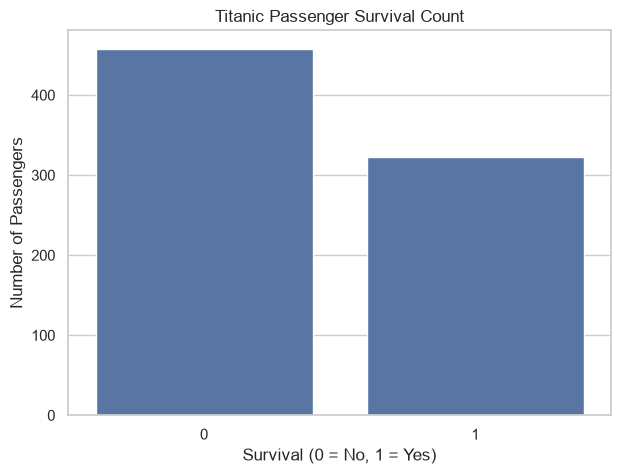

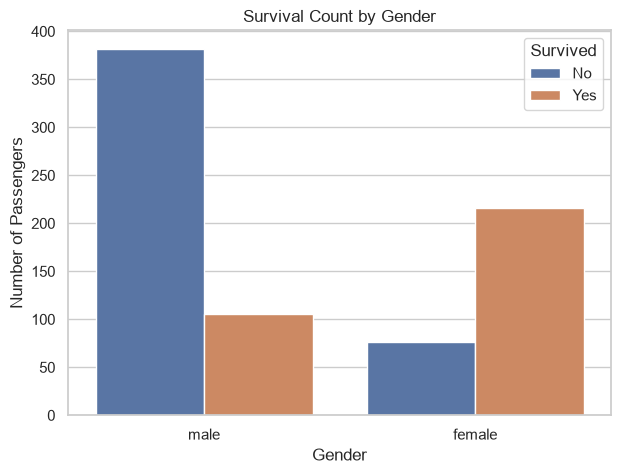

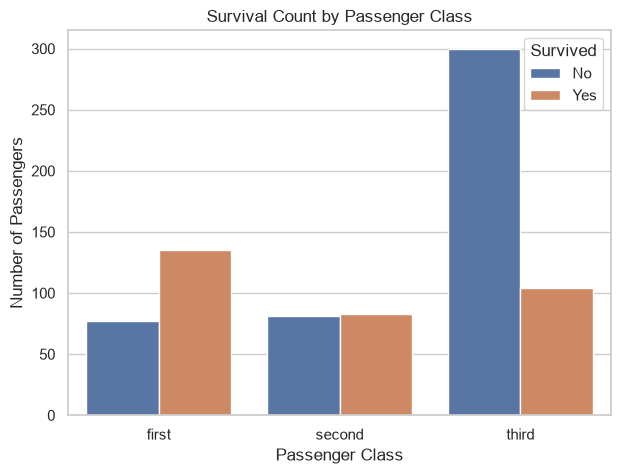

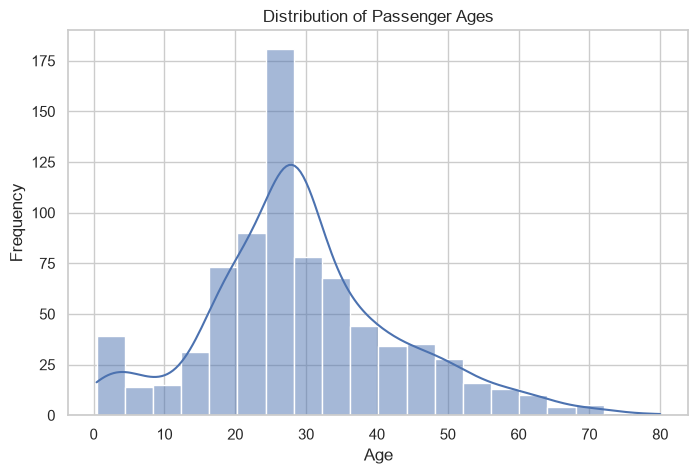

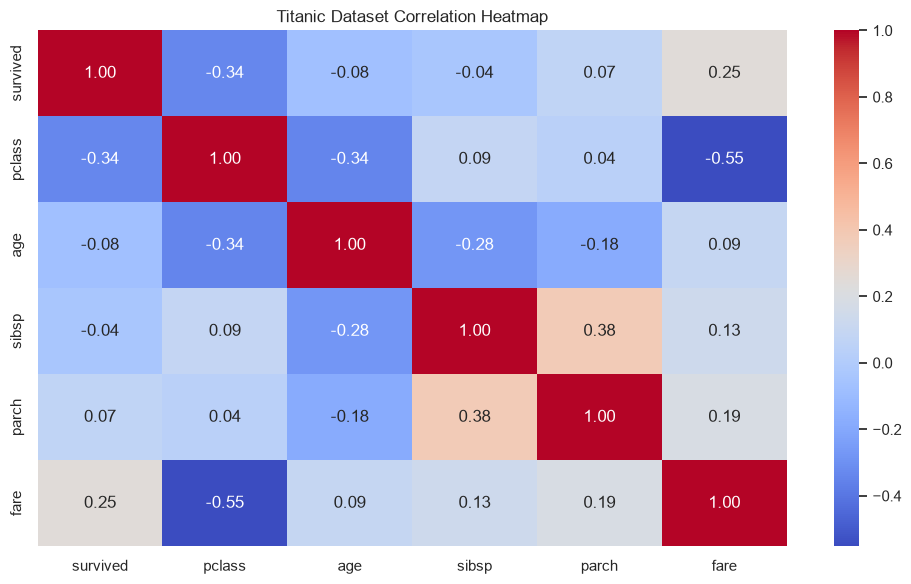

In [7]:

# Survival count analysis

survival_counts = df["survived"].value_counts()

print("Survival Count:")
print(survival_counts)

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="survived")

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.savefig("charts/survival_count.png")
plt.show()

# Survival based on gender

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex", hue="survived")

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(title="Survived", labels=["No", "Yes"])

plt.savefig("charts/survival_by_gender.png")
plt.show()

# Survival based on passenger class

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="class", hue="survived",
              order=["first", "second", "third"])

plt.title("Survival Count by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.legend(title="Survived", labels=["No", "Yes"])

plt.savefig("charts/survival_by_class.png")
plt.show()

# Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.savefig("charts/age_distribution.png")
plt.show()

# Correlation between numerical variables

plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Titanic Dataset Correlation Heatmap")

plt.tight_layout()
plt.savefig("charts/correlation_heatmap.png")
plt.show()


In [8]:

# Overall survival analysis

total_passengers = len(df)

survived = df["survived"].sum()

not_survived = total_passengers - survived

survival_percentage = (survived / total_passengers) * 100

death_percentage = (not_survived / total_passengers) * 100

print("========== SURVIVAL ANALYSIS ==========")

print("Total Passengers:", total_passengers)
print("Survived:", survived)
print("Not Survived:", not_survived)

print("Survival Percentage:", round(survival_percentage, 2), "%")
print("Non-Survival Percentage:", round(death_percentage, 2), "%")


========== SURVIVAL ANALYSIS ==========
Total Passengers: 780
Survived: 322
Not Survived: 458
Survival Percentage: 41.28 %
Non-Survival Percentage: 58.72 %


Survival Percentage by Gender:
sex
female    73.97
male      21.72
Name: survived, dtype: float64


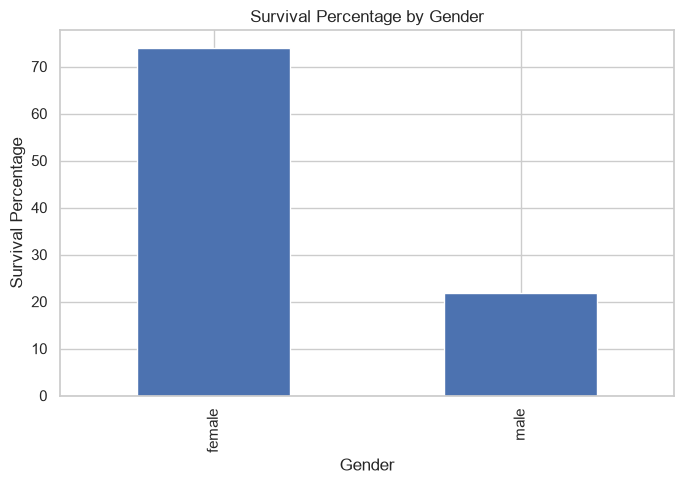

In [9]:

# Survival percentage by gender

gender_survival = df.groupby("sex")["survived"].mean() * 100

print("Survival Percentage by Gender:")
print(gender_survival.round(2))

gender_survival.plot(
    kind="bar",
    figsize=(7, 5),
    title="Survival Percentage by Gender"
)

plt.ylabel("Survival Percentage")
plt.xlabel("Gender")
plt.tight_layout()
plt.savefig("charts/gender_survival_percentage.png")
plt.show()


Survival Percentage by Passenger Class:
class
first     63.68
second    50.61
third     25.74
Name: survived, dtype: float64


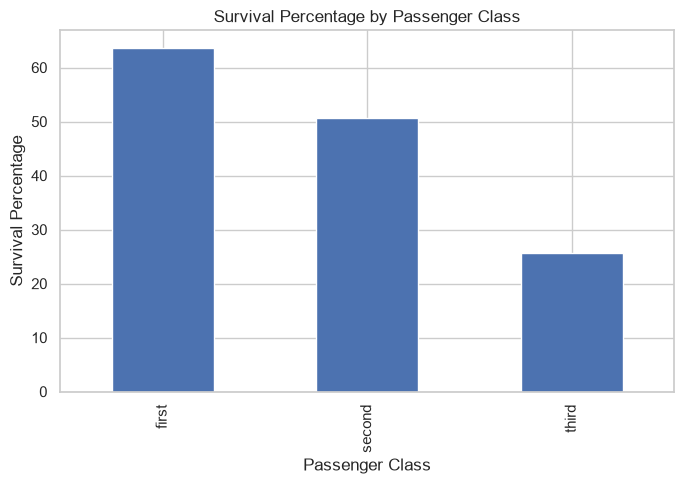

In [10]:

# Survival percentage by passenger class

class_survival = df.groupby("class", observed=True)["survived"].mean() * 100

print("Survival Percentage by Passenger Class:")
print(class_survival.round(2))

class_survival.plot(
    kind="bar",
    figsize=(7, 5),
    title="Survival Percentage by Passenger Class"
)

plt.ylabel("Survival Percentage")
plt.xlabel("Passenger Class")
plt.tight_layout()
plt.savefig("charts/class_survival_percentage.png")
plt.show()


Survival Percentage by Age Group:
age_group
Child          57.35
Teenager       44.78
Young Adult    39.72
Adult          39.79
Senior         23.81
Name: survived, dtype: float64


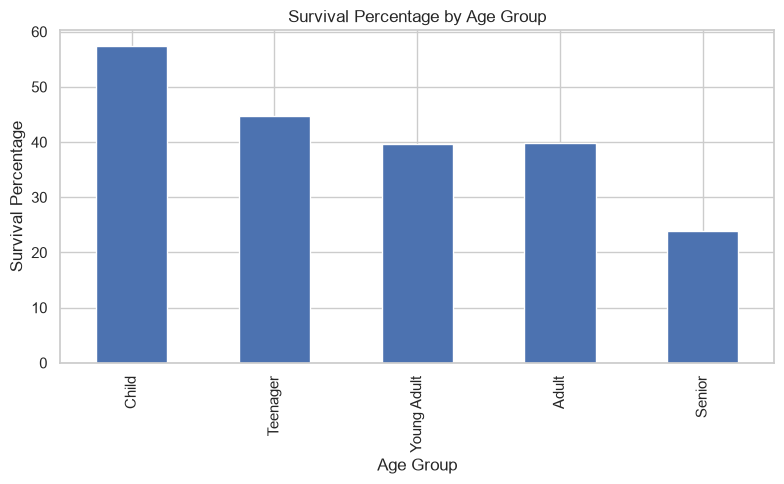

In [11]:

# Create age groups

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

age_survival = df.groupby(
    "age_group", observed=True
)["survived"].mean() * 100

print("Survival Percentage by Age Group:")
print(age_survival.round(2))

age_survival.plot(
    kind="bar",
    figsize=(8, 5),
    title="Survival Percentage by Age Group"
)

plt.ylabel("Survival Percentage")
plt.xlabel("Age Group")
plt.tight_layout()
plt.savefig("charts/age_group_survival.png")
plt.show()


Survival Percentage by Travel Status:
alone
False    51.18
True     33.71
Name: survived, dtype: float64


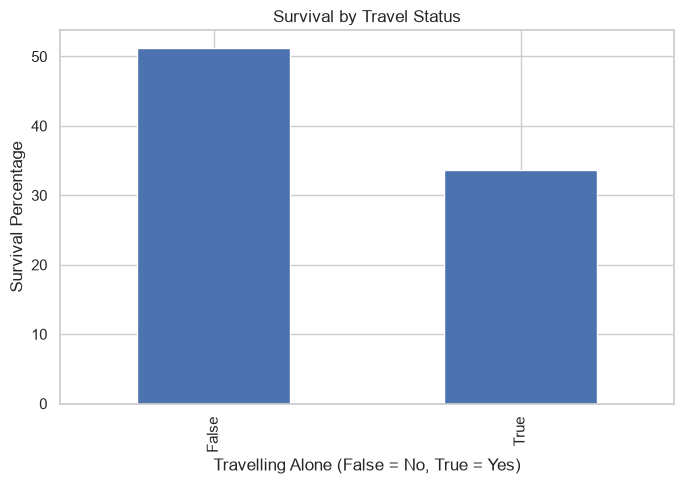

In [12]:

# Compare passengers travelling alone and with family

family_survival = df.groupby("alone")["survived"].mean() * 100

print("Survival Percentage by Travel Status:")
print(family_survival.round(2))

family_survival.plot(
    kind="bar",
    figsize=(7, 5),
    title="Survival by Travel Status"
)

plt.xlabel("Travelling Alone (False = No, True = Yes)")
plt.ylabel("Survival Percentage")
plt.tight_layout()
plt.savefig("charts/family_survival.png")
plt.show()


In [13]:

print("========== FIVE EDA INSIGHTS ==========")

print("\n1. Overall Survival:")
print(f"Survival rate: {survival_percentage:.2f}%")

print("\n2. Gender Analysis:")
print(gender_survival.round(2))

print("\n3. Passenger Class Analysis:")
print(class_survival.round(2))

print("\n4. Age Group Analysis:")
print(age_survival.round(2))

print("\n5. Family Travel Analysis:")
print(family_survival.round(2))


========== FIVE EDA INSIGHTS ==========

1. Overall Survival:
Survival rate: 41.28%

2. Gender Analysis:
sex
female    73.97
male      21.72
Name: survived, dtype: float64

3. Passenger Class Analysis:
class
first     63.68
second    50.61
third     25.74
Name: survived, dtype: float64

4. Age Group Analysis:
age_group
Child          57.35
Teenager       44.78
Young Adult    39.72
Adult          39.79
Senior         23.81
Name: survived, dtype: float64

5. Family Travel Analysis:
alone
False    51.18
True     33.71
Name: survived, dtype: float64


In [14]:

# Save statistical results

df.describe(include="all").T.to_csv(
    "outputs/statistical_summary.csv"
)

df.isnull().sum().to_csv(
    "outputs/missing_values_summary.csv"
)

gender_survival.to_csv(
    "outputs/gender_survival.csv"
)

class_survival.to_csv(
    "outputs/class_survival.csv"
)

age_survival.to_csv(
    "outputs/age_survival.csv"
)

family_survival.to_csv(
    "outputs/family_survival.csv"
)

print("All analysis results saved successfully!")


All analysis results saved successfully!


In [15]:

import os

print("Current Folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())


Current Folder:
C:\Users\subik\Downloads\SWYNEX-Exploratory-Data-Analysis

Files in this folder:
['.ipynb_checkpoints', '.venv', 'charts', 'data', 'outputs', 'SWYNEX_EDA_Analysis']
